# **An Explainable Multi-Modal Game Recommendation System Using Attention-Based Player Preference Reasoning**

**Author**: `Rozhak`   
**Versi**: `5.0`   
**Tujuan**: _Mengembangkan sistem rekomendasi game Steam berbasis deep learning yang memprediksi preferensi pengguna dan menghasilkan penjelasan pada tingkat modalitas untuk setiap rekomendasi._


## **1. Pendahuluan**

Pipeline ini mengimplementasikan sistem rekomendasi game *end-to-end* berbasis dataset *Game Recommendations on Steam*, dengan filtering minimal lima ulasan per pengguna untuk mereduksi data sparsitas dan mengatasi isu *cold-start*.

Model `MultiModalAttentionRecSys` mengintegrasikan *collaborative embeddings*, metadata tabular, dan representasi teks judul game (`all-MiniLM-L6-v2`) ke dimensi laten bersama menggunakan mekanisme *attention* terkondisi preferensi pengguna.

Model dioptimalkan memprediksi target biner `is_recommended` menggunakan `BCELoss` dan `AdamW` (split 80:20), dievaluasi via metrik ROC-AUC dan *confusion matrix*, serta menghasilkan artefak siap pakai untuk inferensi *deployment*.


## **2. Setup Environment & Import Library**

Menyiapkan dependensi eksternal, mengimpor library komputasi dan pemodelan, serta mengonfigurasi perangkat komputasi untuk pipeline rekomendasi.


### **2.1. Dependency Installation**

Menginstal `kaggle` untuk akuisisi dataset melalui API dan `sentence-transformers` untuk ekstraksi representasi teks metadata game.


In [1]:
!pip install -q kaggle sentence-transformers > /dev/null

### **2.2. Library Imports**

Memuat modul PyTorch untuk pemodelan deep learning, scikit-learn dan pandas untuk manipulasi data, serta Sentence Transformers dan utilitas serialisasi.


In [ ]:
import os
import gc
import json
import pickle
import shutil
import warnings
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from torch.utils.data import Dataset, DataLoader, random_split

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix
from sentence_transformers import SentenceTransformer

sns.set_theme(style="whitegrid", palette="muted")
warnings.filterwarnings('ignore')

### **2.3 Compute Device Configuration**

Memeriksa ketersediaan akselerator hardware CUDA dan menetapkan target device PyTorch (`cuda` atau `cpu`) untuk proses training dan inferensi.


In [2]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    gpu_name = torch.cuda.get_device_name(0)
    gpu_count = torch.cuda.device_count()
    print(
        f"[DEVICE] type=CUDA | "
        f"name='{gpu_name}' | "
        f"count={gpu_count} | "
        f"status=AVAILABLE"
    )
else:
    device = torch.device("cpu")
    print(
        f"[DEVICE] type=CPU | "
        f"status=AVAILABLE | "
        f"warning=GPU_NOT_DETECTED"
    )

[DEVICE] type=CUDA | name='Tesla T4' | count=1 | status=AVAILABLE


## **3. Pengumpulan Data & Smart Sampling**

Mengunduh dataset Steam dari Kaggle, memuat metadata game dan interaksi ulasan, serta menyaring data pengguna aktif untuk pemodelan.


### **3.1. Dataset Acquisition & Authentication**

Mengonfigurasi kredensial Kaggle API, mengunduh dataset `antonkozyriev/game-recommendations-on-steam`, dan mengekstrak file arsip ke workspace lokal.


In [3]:
from google.colab import files
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

Saving secrets.json to secrets.json
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [4]:
print(
    f"[DATASET] source=KAGGLE | "
    f"dataset='antonkozyriev/game-recommendations-on-steam' | "
    f"status=DOWNLOADING"
)

!kaggle datasets download -d antonkozyriev/game-recommendations-on-steam
!unzip -q game-recommendations-on-steam.zip

print(
    f"[DATASET] source=KAGGLE | "
    f"dataset='antonkozyriev/game-recommendations-on-steam' | "
    f"status=EXTRACTED"
)

[DATASET] source=KAGGLE | dataset='antonkozyriev/game-recommendations-on-steam' | status=DOWNLOADING
Dataset URL: https://www.kaggle.com/datasets/antonkozyriev/game-recommendations-on-steam
License(s): CC0-1.0
100% 660M/660M [00:07<00:00, 95.7MB/s]

[DATASET] source=KAGGLE | dataset='antonkozyriev/game-recommendations-on-steam' | status=EXTRACTED


### **3.2. Dataset Loading & User Interaction Filtering**

Memuat `games.csv` dan `recommendations.csv`, lalu memfilter interaksi pengguna dengan threshold minimal lima ulasan untuk mengatasi *cold-start* dan mereduksi sparsitas data.


In [5]:
file_metadata = 'games.csv'
df_games = pd.read_csv(file_metadata)

print(
    f"[DATASET] file='{file_metadata}' | "
    f"records={len(df_games)} | "
    f"status=LOADED"
)

[DATASET] file='games.csv' | records=50872 | status=LOADED


In [6]:
columns_to_use = ['app_id', 'user_id', 'is_recommended', 'hours']

df_reco_raw = pd.read_csv(
    'recommendations.csv',
    usecols=columns_to_use
)

print(
    f"[DATASET] file='recommendations.csv' | "
    f"records={df_reco_raw.shape[0]} | "
    f"columns={columns_to_use} | "
    f"status=LOADED"
)

[DATASET] file='recommendations.csv' | records=41154794 | columns=['app_id', 'user_id', 'is_recommended', 'hours'] | status=LOADED


In [7]:
user_counts = df_reco_raw['user_id'].value_counts()
active_users = user_counts[user_counts >= 5].index
df_reco = df_reco_raw[df_reco_raw['user_id'].isin(active_users)].copy()

del df_reco_raw
gc.collect()

print(
    f"[FILTERING] method='K-CORE' | "
    f"threshold=5 | "
    f"filtered_records={len(df_reco)} | "
    f"unique_users={df_reco['user_id'].nunique()} | "
    f"unique_games={df_reco['app_id'].nunique()} | "
    f"status=PASSED"
)

[FILTERING] method='K-CORE' | threshold=5 | filtered_records=22444312 | unique_users=1910831 | unique_games=37478 | status=PASSED


### **3.2 Preview Data (Hasil Preprocessing)**

Memeriksa struktur kolom, tipe data, dan sampel awal dari `df_games` dan `df_reco` pasca-filtering sebelum masuk ke tahap analisis dan rekayasa fitur.


In [8]:
print(
    f"[PREVIEW] dataset='df_games' | "
    f"samples=5 | "
    f"status=DISPLAYED"
)
display(df_games.head())

[PREVIEW] dataset='df_games' | samples=5 | status=DISPLAYED


,app_id,title,date_release,win,mac,linux,rating,positive_ratio,user_reviews,price_final,price_original,discount,steam_deck
0,13500,Prince of Persia: Warrior Within™,2008-11-21,True,False,False,Very Positive,84,2199,9.99,9.99,0.0,True
1,22364,BRINK: Agents of Change,2011-08-03,True,False,False,Positive,85,21,2.99,2.99,0.0,True
2,113020,Monaco: What's Yours Is Mine,2013-04-24,True,True,True,Very Positive,92,3722,14.99,14.99,0.0,True
3,226560,Escape Dead Island,2014-11-18,True,False,False,Mixed,61,873,14.99,14.99,0.0,True
4,249050,Dungeon of the ENDLESS™,2014-10-27,True,True,False,Very Positive,88,8784,11.99,11.99,0.0,True


In [9]:
print(
    f"[PREVIEW] dataset='df_reco' | "
    f"samples=5 | "
    f"status=DISPLAYED"
)
display(df_reco.head())

[PREVIEW] dataset='df_reco' | samples=5 | status=DISPLAYED


,app_id,is_recommended,hours,user_id
0,975370,True,36.3,51580
12,1938090,True,46.7,161081
16,635260,True,177.0,76583
21,1938090,True,7.4,664486
22,534380,True,40.6,22793


## **4. Exploratory Data Analysis (EDA)**

Menganalisis distribusi target rekomendasi, statistik jam bermain, karakteristik harga dan platform OS, serta game dengan frekuensi interaksi tertinggi.


### **4.1 Distribusi Target & Distribusi Jam Bermain**

Memvisualisasikan proporsi kelas target `is_recommended` untuk mendeteksi *imbalance* kelas dan distribusi jam bermain pengguna dalam skala logaritmik.


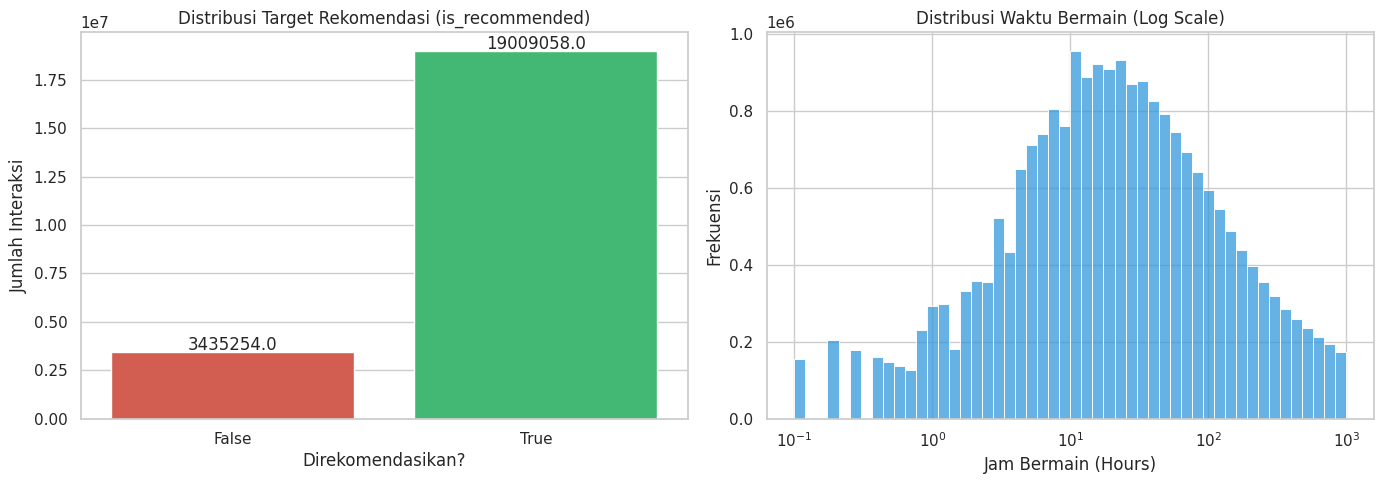

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df_reco, x='is_recommended', ax=axes[0], palette=['#e74c3c', '#2ecc71'])
axes[0].set_title('Distribusi Target Rekomendasi (is_recommended)', fontsize=12)
axes[0].set_xlabel('Direkomendasikan?')
axes[0].set_ylabel('Jumlah Interaksi')

for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

sns.histplot(data=df_reco, x='hours', bins=50, log_scale=True, ax=axes[1], color='#3498db')
axes[1].set_title('Distribusi Waktu Bermain (Log Scale)', fontsize=12)
axes[1].set_xlabel('Jam Bermain (Hours)')
axes[1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

### **4.2 Distribusi Platform OS & Harga Game**

Memeriksa sebaran kompatibilitas multi-platform (Windows, macOS, Linux) dan distribusi harga akhir game (`price_final`) pada rentang persentil ke-95.


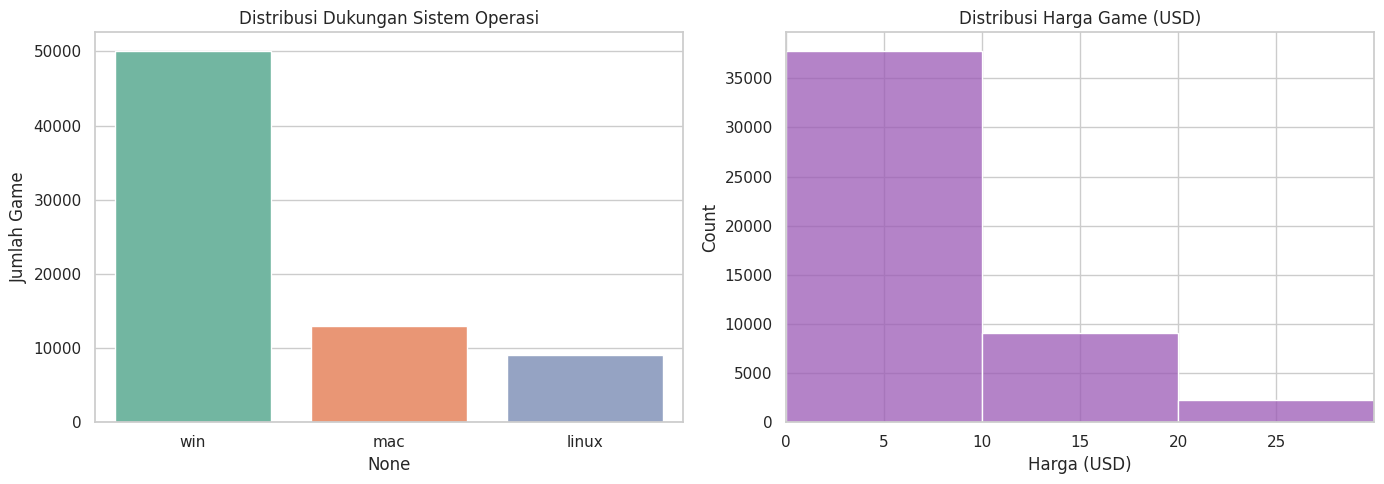

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

os_counts = df_games[['win', 'mac', 'linux']].sum()
sns.barplot(x=os_counts.index, y=os_counts.values, ax=axes[0], palette='Set2')
axes[0].set_title('Distribusi Dukungan Sistem Operasi', fontsize=12)
axes[0].set_ylabel('Jumlah Game')

sns.histplot(data=df_games, x='price_final', bins=30, ax=axes[1], color='#9b59b6')
axes[1].set_title('Distribusi Harga Game (USD)', fontsize=12)
axes[1].set_xlabel('Harga (USD)')
axes[1].set_xlim(0, df_games['price_final'].quantile(0.95))

plt.tight_layout()
plt.show()

### **4.3 Top 5 Game Paling Banyak Direview dalam Subset**

Mengidentifikasi lima judul game dengan volume interaksi ulasan terbanyak dalam subset data interaksi hasil penyaringan.


In [12]:
top_games_id = df_reco['app_id'].value_counts().head(5).index
top_games_names = df_games[df_games['app_id'].isin(top_games_id)][['app_id', 'title']]
print(
    f"[EDA] analysis='TOP_GAMES' | "
    f"count=5 | "
    f"status=DISPLAYED"
)
display(top_games_names)

[EDA] analysis='TOP_GAMES' | count=5 | status=DISPLAYED


,app_id,title
12800,292030,The Witcher® 3: Wild Hunt
13181,377160,Fallout 4
14163,1091500,Cyberpunk 2077
16071,374320,DARK SOULS™ III
47380,440,Team Fortress 2


## **5. Feature Engineering (Multi-Modal Extraction)**

Mentransformasikan identitas interaksi, metadata tabular, dan teks judul game menjadi representasi numerik multimodal yang siap diumpankan ke model.


### **5.1 Collaborative Features (ID Mapping)**

Memetakan `user_id` dan `app_id` ke indeks integer kontinu (`user_idx`, `game_idx`) sebagai lookup table embedding kolaboratif model.


In [13]:
user2idx = {u: i for i, u in enumerate(df_reco['user_id'].unique())}
idx2user = {i: u for u, i in user2idx.items()}

valid_games = df_reco['app_id'].unique()
df_games = df_games[df_games['app_id'].isin(valid_games)].copy()

game2idx = {g: i for i, g in enumerate(df_games['app_id'].unique())}
idx2game = {i: g for g, i in game2idx.items()}

df_reco['user_idx'] = df_reco['user_id'].map(user2idx)
df_reco['game_idx'] = df_reco['app_id'].map(game2idx)
df_reco = df_reco.dropna(subset=['game_idx'])
df_reco['game_idx'] = df_reco['game_idx'].astype(int)

print(
    f"[FEATURE] type=COLLABORATIVE | "
    f"users={len(user2idx)} | "
    f"games={len(game2idx)} | "
    f"status=MAPPED"
)

[FEATURE] type=COLLABORATIVE | users=1910831 | games=37478 | status=MAPPED


### **5.2 Tabular Features (Metadata Game)**

Mengekstrak fitur metadata platform dan numerik, mengimputasi nilai hilang, menormalisasi data dengan `StandardScaler`, dan menyimpannya dalam `tabular_dict` berbasis `game_idx`.


In [14]:
bool_cols = ['win', 'mac', 'linux', 'steam_deck']

bool_cols = [c for c in bool_cols if c in df_games.columns]
for col in bool_cols:
    df_games[col] = df_games[col].astype(int)

if 'rating' in df_games.columns:
    df_games['rating_encoded'] = LabelEncoder().fit_transform(df_games['rating'].fillna('Unknown'))
else:
    df_games['rating_encoded'] = 0

num_cols = ['positive_ratio', 'price_final', 'discount']
num_cols = [c for c in num_cols if c in df_games.columns]

df_games['price_original'] = df_games['price_final']

scaler = StandardScaler()
df_games[num_cols] = scaler.fit_transform(df_games[num_cols].fillna(0))

tabular_cols = bool_cols + (['rating_encoded'] if 'rating' in df_games.columns else []) + num_cols
num_tab_feat = len(tabular_cols)

tabular_dict = {
    game2idx[row['app_id']]: row[tabular_cols].values.astype(np.float32)
    for _, row in df_games.iterrows()
}

contoh_idx = list(tabular_dict.keys())[0]

print(
    f"[FEATURE] type=TABULAR | "
    f"dimension={num_tab_feat} | "
    f"sample_game_idx={contoh_idx} | "
    f"sample_values={tabular_dict[contoh_idx].tolist()} | "
    f"status=READY"
)

[FEATURE] type=TABULAR | dimension=8 | sample_game_idx=0 | sample_values=[1.0, 0.0, 0.0, 1.0, 8.0, 0.4183696210384369, 0.1416589617729187, -0.30550938844680786] | status=READY


### **5.3 Textual Features (NLP Embeddings)**

Mengekstraksi representasi semantik judul game menjadi vektor embedding 384-dimensi menggunakan `all-MiniLM-L6-v2` dan menyimpannya dalam `textual_dict` berbasis `game_idx`.


In [15]:
print(
    f"[FEATURE] type=TEXTUAL | "
    f"model='all-MiniLM-L6-v2' | "
    f"status=EXTRACTING"
)

nlp_model = SentenceTransformer('all-MiniLM-L6-v2', device=str(device))

titles = df_games['title'].fillna("Unknown Game").tolist()
title_embeddings = nlp_model.encode(titles, show_progress_bar=True)
num_txt_feat = title_embeddings.shape[1]

textual_dict = {
    game2idx[row[1]['app_id']]: title_embeddings[i]
    for i, row in enumerate(df_games.iterrows())
}

print(
    f"[FEATURE] type=TEXTUAL | "
    f"model='all-MiniLM-L6-v2' | "
    f"dimension={num_txt_feat} | "
    f"sample_vector_head={title_embeddings[0][:5].tolist()} | "
    f"status=READY"
)

[FEATURE] type=TEXTUAL | model='all-MiniLM-L6-v2' | status=EXTRACTING


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (6 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/1172 [00:00<?, ?it/s]

[FEATURE] type=TEXTUAL | model='all-MiniLM-L6-v2' | dimension=384 | sample_vector_head=[-0.10182664543390274, 0.06629295647144318, -0.025290392339229584, -0.008050085976719856, -0.04060180112719536] | status=READY


## **6. Dataset & Arsitektur Model PyTorch**

Mengonstruksi data pipeline PyTorch Dataset/DataLoader dan mendefinisikan arsitektur jaringan rekomendasi multimodal berbasis mekanisme attention.


### **6.1 PyTorch Dataset Class**

Membangun `GameRecommendationDataset` untuk menyatukan indeks pengguna, indeks game, fitur tabular, embedding teks, dan label biner ke dalam format PyTorch Tensor per batch.


In [16]:
class GameRecommendationDataset(Dataset):
    def __init__(self, df):
        self.users = torch.tensor(df['user_idx'].values, dtype=torch.long)
        self.games = torch.tensor(df['game_idx'].values, dtype=torch.long)
        self.labels = torch.tensor(df['is_recommended'].astype(float).values, dtype=torch.float32)

    def __len__(self):
        return len(self.users)

    def __getitem__(self, idx):
        g_idx = self.games[idx].item()
        return (
            self.users[idx],
            self.games[idx],
            torch.tensor(tabular_dict[g_idx], dtype=torch.float32),
            torch.tensor(textual_dict[g_idx], dtype=torch.float32),
            self.labels[idx]
        )

### **6.2 Multi-Modal Attention Architecture**

Mengimplementasikan arsitektur `MultiModalAttentionRecSys` yang memproyeksikan fitur kolaboratif, tabular, dan teks ke dimensi laten bersama, menghitung bobot attention terkondisi preferensi pengguna, dan menghasilkan probabilitas rekomendasi serta bobot atribusi modalitas.


In [17]:
class MultiModalAttentionRecSys(nn.Module):
    def __init__(self, n_users, n_games, n_tab, n_txt, hidden_dim=64):
        super().__init__()
        self.u_emb = nn.Embedding(n_users, hidden_dim)
        self.g_emb = nn.Embedding(n_games, hidden_dim)
        self.tab_proj = nn.Sequential(nn.Linear(n_tab, hidden_dim), nn.ReLU())
        self.txt_proj = nn.Sequential(nn.Linear(n_txt, hidden_dim), nn.ReLU())

        self.q_layer = nn.Linear(hidden_dim, hidden_dim)
        self.k_layer = nn.Linear(hidden_dim, hidden_dim)

        self.pred_layer = nn.Sequential(
            nn.Linear(hidden_dim, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )

    def forward(self, u_idx, g_idx, tab_f, txt_f, return_attention=False):
        u = self.u_emb(u_idx)
        g = self.g_emb(g_idx)
        t = self.tab_proj(tab_f)
        x = self.txt_proj(txt_f)

        modalities = torch.stack([g, t, x], dim=1)

        query = self.q_layer(u).unsqueeze(1)
        keys = self.k_layer(modalities)

        att_scores = torch.bmm(query, keys.transpose(1, 2))
        att_weights = F.softmax(att_scores, dim=-1)

        context = torch.bmm(att_weights, modalities).squeeze(1)

        pred = self.pred_layer(context).squeeze(-1)

        if return_attention:
            return pred, att_weights.squeeze(1)
        return pred

## **7. Training & Validation Loop**

Mengonfigurasi pembagian dataset, parameter optimisasi, dan mengeksekusi iterasi pelatihan serta validasi model secara berkala per epoch.


### **7.1. Training Configuration & Data Split**

Membagi dataset menjadi 80% train dan 20% validation, menyiapkan `DataLoader` (batch size 1.024), serta mengonfigurasi optimizer AdamW dan fungsi loss `BCELoss`.


In [18]:
dataset = GameRecommendationDataset(df_reco)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_ds, val_ds = random_split(dataset, [train_size, val_size])

BATCH_SIZE = 1024
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

model = MultiModalAttentionRecSys(
    n_users=len(user2idx),
    n_games=len(game2idx),
    n_tab=num_tab_feat,
    n_txt=num_txt_feat
).to(device)

criterion = nn.BCELoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)

EPOCHS = 5
best_auc = 0.0
train_losses, val_aucs = [], []

print(
    f"[TRAINING] epochs={EPOCHS} | "
    f"batch_size={BATCH_SIZE} | "
    f"optimizer='AdamW' | "
    f"loss='BCELoss' | "
    f"device='{device}' | "
    f"status=STARTED"
)

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    for u, g, tab, txt, y in train_loader:
        u, g, tab, txt, y = u.to(device), g.to(device), tab.to(device), txt.to(device), y.to(device)

        optimizer.zero_grad()
        preds = model(u, g, tab, txt)
        loss = criterion(preds, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_train_loss = total_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    model.eval()
    val_preds, val_labels = [], []
    with torch.no_grad():
        for u, g, tab, txt, y in val_loader:
            u, g, tab, txt = u.to(device), g.to(device), tab.to(device), txt.to(device)
            preds = model(u, g, tab, txt)
            val_preds.extend(preds.cpu().numpy())
            val_labels.extend(y.numpy())

    auc = roc_auc_score(val_labels, val_preds)
    val_preds_bin = [1 if p >= 0.5 else 0 for p in val_preds]
    acc = accuracy_score(val_labels, val_preds_bin)

    val_aucs.append(auc)

    print(
        f"[TRAINING] epoch={epoch + 1}/{EPOCHS} | "
        f"train_loss={avg_train_loss:.4f} | "
        f"val_auc={auc:.4f} | "
        f"val_acc={acc:.4f} | "
        f"status=COMPLETED"
    )

    if auc > best_auc:
        best_auc = auc
        torch.save(model.state_dict(), 'best_recsys_model.pth')
        print(
            f"[CHECKPOINT] model='best_recsys_model.pth' | "
            f"epoch={epoch + 1} | "
            f"val_auc={best_auc:.4f} | "
            f"status=SAVED"
        )

[TRAINING] epochs=5 | batch_size=1024 | optimizer='AdamW' | loss='BCELoss' | device='cuda' | status=STARTED
[TRAINING] epoch=1/5 | train_loss=0.3813 | val_auc=0.7357 | val_acc=0.8508 | status=COMPLETED
[CHECKPOINT] model='best_recsys_model.pth' | epoch=1 | val_auc=0.7357 | status=SAVED
[TRAINING] epoch=2/5 | train_loss=0.3796 | val_auc=0.7362 | val_acc=0.8508 | status=COMPLETED
[CHECKPOINT] model='best_recsys_model.pth' | epoch=2 | val_auc=0.7362 | status=SAVED
[TRAINING] epoch=3/5 | train_loss=0.3794 | val_auc=0.7362 | val_acc=0.8507 | status=COMPLETED
[TRAINING] epoch=4/5 | train_loss=0.3794 | val_auc=0.7363 | val_acc=0.8506 | status=COMPLETED
[CHECKPOINT] model='best_recsys_model.pth' | epoch=4 | val_auc=0.7363 | status=SAVED
[TRAINING] epoch=5/5 | train_loss=0.3793 | val_auc=0.7365 | val_acc=0.8507 | status=COMPLETED
[CHECKPOINT] model='best_recsys_model.pth' | epoch=5 | val_auc=0.7365 | status=SAVED


### **7.1 Visualisasi Hasil Training**

Memvisualisasikan konvergensi training loss dan dinamika metrik validasi ROC-AUC per epoch untuk mengevaluasi stabilitas pelatihan dan indikasi overfitting.


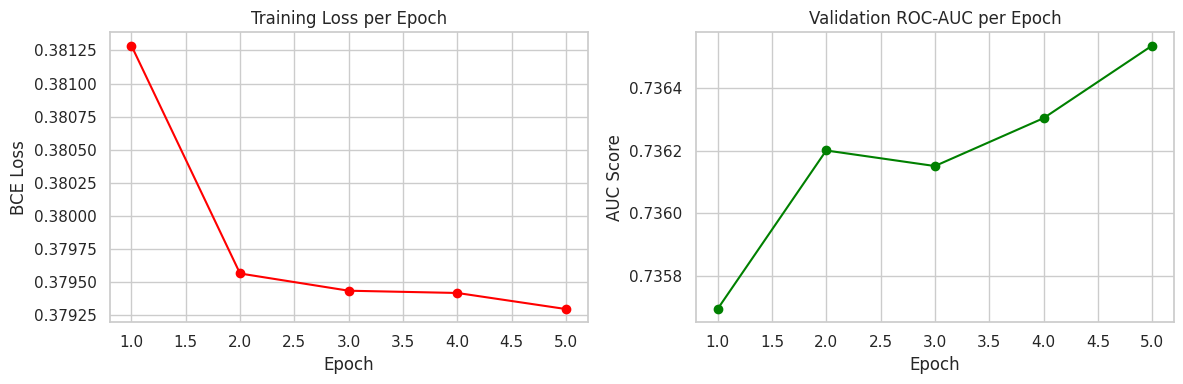

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, EPOCHS+1), train_losses, marker='o', color='red')
axes[0].set_title('Training Loss per Epoch')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('BCE Loss')

axes[1].plot(range(1, EPOCHS+1), val_aucs, marker='o', color='green')
axes[1].set_title('Validation ROC-AUC per Epoch')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('AUC Score')
plt.tight_layout()
plt.show()

### **7.2 Evaluasi Prediksi (Confusion Matrix)**

Mengevaluasi performa klasifikasi biner pada data validasi dengan threshold 0.5 melalui confusion matrix (TP, TN, FP, FN) dan metrik akurasi.


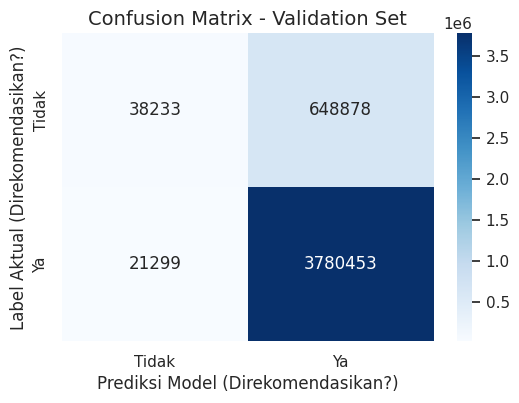

In [20]:
cm = confusion_matrix(val_labels, val_preds_bin)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Tidak', 'Ya'],
            yticklabels=['Tidak', 'Ya'])
plt.title('Confusion Matrix - Validation Set', fontsize=14)
plt.xlabel('Prediksi Model (Direkomendasikan?)')
plt.ylabel('Label Aktual (Direkomendasikan?)')
plt.show()

## **8. Model Export & Artifact Serialization**

Mengekspor bobot model, file konfigurasi, pemetaan ID, metadata katalog, dan matriks fitur multimodal ke direktori terpusat untuk deployment inferensi.


### **8.1 Model Checkpoint & Configuration**

Menyimpan PyTorch `state_dict` bobot terbaik ke `best_recsys_model.pth` dan parameter dimensi arsitektur ke `model_config.json`.


In [21]:
export_dir = 'artifacts'
os.makedirs(export_dir, exist_ok=True)

checkpoint_src = 'best_recsys_model.pth'
checkpoint_dst = os.path.join(export_dir, 'best_recsys_model.pth')
if os.path.exists(checkpoint_src):
    if os.path.abspath(checkpoint_src) != os.path.abspath(checkpoint_dst):
        shutil.copy2(checkpoint_src, checkpoint_dst)
else:
    torch.save(model.state_dict(), checkpoint_dst)

print(
    f"[ARTIFACT] type=MODEL_CHECKPOINT | "
    f"path='{checkpoint_dst}' | "
    f"status=EXPORTED"
)

model_config = {
    'n_users': int(len(user2idx)),
    'n_games': int(len(game2idx)),
    'n_tab': int(num_tab_feat),
    'n_txt': int(num_txt_feat),
    'hidden_dim': 64
}
config_path = os.path.join(export_dir, 'model_config.json')
with open(config_path, 'w', encoding='utf-8') as f:
    json.dump(model_config, f, indent=4)

print(
    f"[CONFIG] type=MODEL_CONFIG | "
    f"path='{config_path}' | "
    f"n_users={model_config['n_users']} | "
    f"n_games={model_config['n_games']} | "
    f"hidden_dim={model_config['hidden_dim']} | "
    f"status=EXPORTED"
)

[ARTIFACT] type=MODEL_CHECKPOINT | path='artifacts/best_recsys_model.pth' | status=EXPORTED
[CONFIG] type=MODEL_CONFIG | path='artifacts/model_config.json' | n_users=1910831 | n_games=37478 | hidden_dim=64 | status=EXPORTED


### **8.2 ID Mapping & Game Metadata**

Menserilisasi dictionary mapping ID (`user2idx`, `game2idx`, `idx2game`) ke `mappings.pkl` dan mengekspor metadata game ke `games_metadata.csv`.


In [22]:
mappings = {
    'user2idx': user2idx,
    'game2idx': game2idx,
    'idx2game': idx2game
}
mappings_path = os.path.join(export_dir, 'mappings.pkl')
with open(mappings_path, 'wb') as f:
    pickle.dump(mappings, f, protocol=pickle.HIGHEST_PROTOCOL)

print(
    f"[MAPPINGS] type=ID_MAPPING | "
    f"path='{mappings_path}' | "
    f"users={len(user2idx)} | "
    f"games={len(game2idx)} | "
    f"status=EXPORTED"
)

metadata_cols = [
    'app_id', 'title', 'rating', 'price_original', 'price_final',
    'discount', 'positive_ratio'
]
platform_cols = ['win', 'mac', 'linux', 'steam_deck']
cols_to_export = [c for c in metadata_cols + platform_cols if c in df_games.columns]

df_games_export = df_games.copy()
if 'game_idx' not in df_games_export.columns:
    df_games_export['game_idx'] = df_games_export['app_id'].map(game2idx)

df_games_export = df_games_export.sort_values('game_idx').reset_index(drop=True)
metadata_csv_path = os.path.join(export_dir, 'games_metadata.csv')
export_columns = ['game_idx'] + [c for c in cols_to_export if c != 'game_idx']
df_games_export[export_columns].to_csv(metadata_csv_path, index=False)

print(
    f"[METADATA] type=GAME_METADATA | "
    f"path='{metadata_csv_path}' | "
    f"records={len(df_games_export)} | "
    f"status=EXPORTED"
)

[MAPPINGS] type=ID_MAPPING | path='artifacts/mappings.pkl' | users=1910831 | games=37478 | status=EXPORTED
[METADATA] type=GAME_METADATA | path='artifacts/games_metadata.csv' | records=37478 | status=EXPORTED


### **8.3 Multi-Modal Feature Matrices**

Menyimpan matriks fitur tabular dan embedding teks yang telah diurutkan berdasarkan `game_idx` ke dalam format biner `tabular_features.npy` dan `textual_features.npy`.


In [23]:
tabular_matrix = np.array([tabular_dict[i] for i in range(len(game2idx))], dtype=np.float32)
tabular_path = os.path.join(export_dir, 'tabular_features.npy')
np.save(tabular_path, tabular_matrix)

print(
    f"[FEATURE] type=TABULAR_MATRIX | "
    f"path='{tabular_path}' | "
    f"shape={list(tabular_matrix.shape)} | "
    f"status=EXPORTED"
)

textual_matrix = np.array([textual_dict[i] for i in range(len(game2idx))], dtype=np.float32)
textual_path = os.path.join(export_dir, 'textual_features.npy')
np.save(textual_path, textual_matrix)

print(
    f"[FEATURE] type=TEXTUAL_MATRIX | "
    f"path='{textual_path}' | "
    f"shape={list(textual_matrix.shape)} | "
    f"status=EXPORTED"
)

[FEATURE] type=TABULAR_MATRIX | path='artifacts/tabular_features.npy' | shape=[37478, 8] | status=EXPORTED
[FEATURE] type=TEXTUAL_MATRIX | path='artifacts/textual_features.npy' | shape=[37478, 384] | status=EXPORTED


### **8.4 Deployment Artifact Packaging**

Mengompresi seluruh file dalam direktori `artifacts` menjadi arsip tunggal `artifacts.zip` untuk integrasi pipeline inferensi dan deployment aplikasi.


In [24]:
zip_path = shutil.make_archive('artifacts', 'zip', export_dir)

print(
    f"[PACKAGE] format=ZIP | "
    f"archive='{zip_path}' | "
    f"source_dir='{export_dir}' | "
    f"status=READY"
)

[PACKAGE] format=ZIP | archive='/content/artifacts.zip' | source_dir='artifacts' | status=READY


## **9. Kesimpulan**

Sistem XAIGameRecommender berhasil memodelkan probabilitas preferensi rekomendasi game (`is_recommended`) secara stabil menggunakan PyTorch multimodal attention yang menyatukan sinyal kolaboratif, metadata tabular, dan representasi teks judul.

Seluruh komponen inferensi telah diserialisasi ke direktori `artifacts` (`.pth`, `.json`, `.pkl`, `.csv`, `.npy`), dengan mekanisme *attention* yang menyediakan transparansi prediksi berupa bobot atribusi kontribusi antar-modalitas.

Meskipun konvergensi validasi tercapai, implementasi tingkat produksi disarankan menguji ketahanan model terhadap *temporal drift* serta mengadopsi metrik rekomendasi berbasis ranking (NDCG@K dan HitRate@K) sebelum integrasi antarmuka.
